# Fraudulent Job Posting Detection

**Author:** Yukthi Kedarnatha Mathad  
**Module:** IS41070 Machine Learning Foundations
**Dataset:** [Real / Fake Job Postings (EMSCAD)](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction) — Employment Scam Aegean Dataset

## Project Overview

Online job boards are frequently exploited by scammers who post fake job listings to harvest personal
data, extract application fees, or conduct phishing attacks against job seekers. This project builds a
machine learning pipeline to **automatically classify a job posting as genuine or fraudulent**, based on
the posting's text content (title, description, requirements, benefits) and structured metadata
(employment type, required experience/education, industry, function, and posting flags).

This is a **binary classification task** (`fraudulent`: 0 = genuine, 1 = fraudulent).

The project is organised into four parts, matching the assignment brief:
1. Data Understanding (this section)
2. Data Preparation & Modeling
3. Evaluation
4. Reflection

A fixed random seed is used throughout for reproducibility.

In [1]:
import numpy as np
import random

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
print(f"Random seed set to {RANDOM_SEED} for reproducibility.")

Random seed set to 42 for reproducibility.


---
# Task 1: Data Understanding

## 1.1 Dataset Introduction

**Source:** Employment Scam Aegean Dataset (EMSCAD), hosted on Kaggle as *"Real or Fake Job Postings"*.
This is a well-known benchmark dataset used in several published fraud-detection studies, which gives us
reference points to compare against later in Task 3.

**What it contains:** 17,880 job postings scraped from a job board, with 18 columns:

| Column | Type | Description |
|---|---|---|
| `job_id` | id | Row identifier |
| `title` | text | Job title |
| `location` | categorical | Country/state/city of posting |
| `department` | categorical | Department within company |
| `salary_range` | text | Free-text salary range |
| `company_profile` | text | Company description |
| `description` | text | Job description |
| `requirements` | text | Candidate requirements |
| `benefits` | text | Listed benefits |
| `telecommuting` | binary | Remote work flag |
| `has_company_logo` | binary | Whether a company logo is present |
| `has_questions` | binary | Whether screening questions are present |
| `employment_type` | categorical | Full-time / part-time / contract / etc. |
| `required_experience` | categorical | Entry level / mid-senior / etc. |
| `required_education` | categorical | Degree requirement |
| `industry` | categorical | Industry sector |
| `function` | categorical | Job function |
| `fraudulent` | **target** | 1 = fraudulent posting, 0 = genuine |

**Prediction task:** Using the text and metadata of a job posting, predict whether it is fraudulent
(`fraudulent = 1`) or genuine (`fraudulent = 0`).

**Why this matters:** Fake job postings cause real financial and psychological harm to job seekers,
often people who are already vulnerable (unemployed, financially stressed). Automatically flagging
suspicious postings could help job boards protect users before harm occurs — this framing also sets up
the ethics discussion in Task 4.

## 1.2 Load the Data

In [2]:
import pandas as pd

df = pd.read_csv("data/fake_job_postings.csv")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)

Shape: 17880 rows, 18 columns


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

The dataset loaded correctly with 17,880 rows and 18 columns, matching the documented source.
All text-heavy columns (`company_profile`, `description`, `requirements`, `benefits`) are stored as
strings (object dtype), and the three engagement flags plus the target are integers.

## 1.3 Exploratory Data Analysis

### 1.3.1 Data Overview: Target Distribution

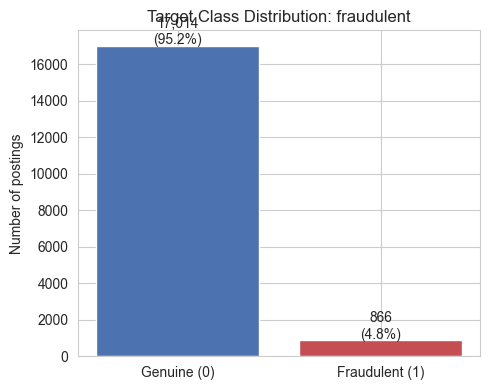

fraudulent
0    17014
1      866
Name: count, dtype: int64
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

counts = df['fraudulent'].value_counts()
pct = df['fraudulent'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Genuine (0)', 'Fraudulent (1)'], counts.values, color=['#4C72B0', '#C44E52'])
for bar, p in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{bar.get_height():,}\n({p:.1f}%)', ha='center', fontsize=10)
ax.set_ylabel('Number of postings')
ax.set_title('Target Class Distribution: fraudulent')
plt.tight_layout()
plt.savefig('fig_target_balance.png', dpi=110)
plt.show()

print(counts)
print(pct.round(2))

**Finding — severe class imbalance:** Only **866 postings (4.84%)** are fraudulent, versus **17,014
(95.16%)** genuine. This has direct implications for the rest of the project:
- **Accuracy is a misleading metric** here — a model that always predicts "genuine" would score 95.16%
  accuracy while being completely useless. This sets our baseline: any model must clearly beat 95.16%
  accuracy *and* demonstrate real recall on the fraud class to be considered useful.
- We will need to consider **F1-score, precision, recall, and PR-AUC** (rather than accuracy or even
  ROC-AUC alone) when evaluating models in Task 3.
- We may need to address the imbalance directly in Task 2 (e.g., class weighting, resampling).

### 1.3.2 Missing Data Check

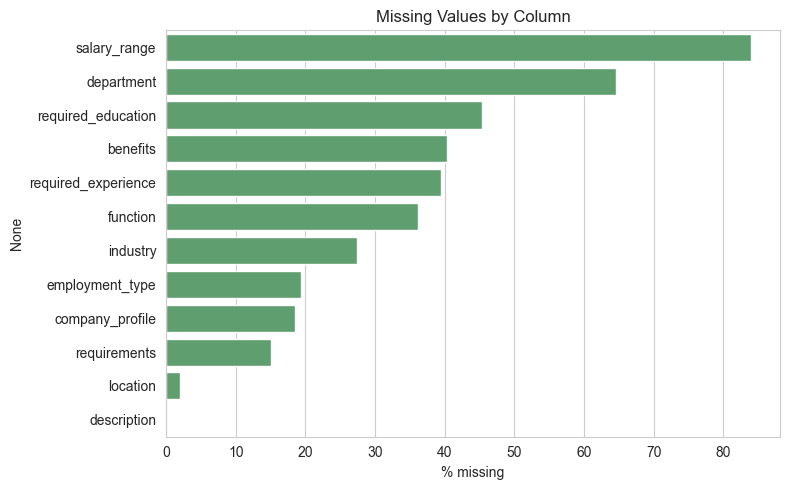

salary_range           84.0
department             64.6
required_education     45.3
benefits               40.3
required_experience    39.4
function               36.1
industry               27.4
employment_type        19.4
company_profile        18.5
requirements           15.1
location                1.9
description             0.0
dtype: float64

In [5]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing.values, y=missing.index, ax=ax, color='#55A868')
ax.set_xlabel('% missing')
ax.set_title('Missing Values by Column')
plt.tight_layout()
plt.savefig('fig_missingness.png', dpi=110)
plt.show()

missing.round(1)

**Finding:** Several columns have substantial missingness:
- `salary_range` is missing in **84%** of postings — too sparse to use directly as a numeric feature, but
  its *presence/absence* could itself be a useful engineered flag (scam postings may be less likely to
  list a real salary, or may use it as bait — we'll check this below).
- `department` (65%), `required_education` (45%), `benefits` (40%), `required_experience` (39%),
  `function` (36%), and `industry` (27%) all have meaningful missingness.
- Core text fields (`description`, `title`) have **no missing values**, and `company_profile` /
  `requirements` are only modestly incomplete (18.5% and 15.1%).

This tells us: for categorical metadata, missingness itself may be informative (fraudulent postings may
provide less detail to avoid scrutiny), so we should consider an explicit **"Missing/Unknown" category**
during encoding in Task 2, rather than dropping rows or naively imputing.

### 1.3.3 Does Missingness Relate to Fraud?

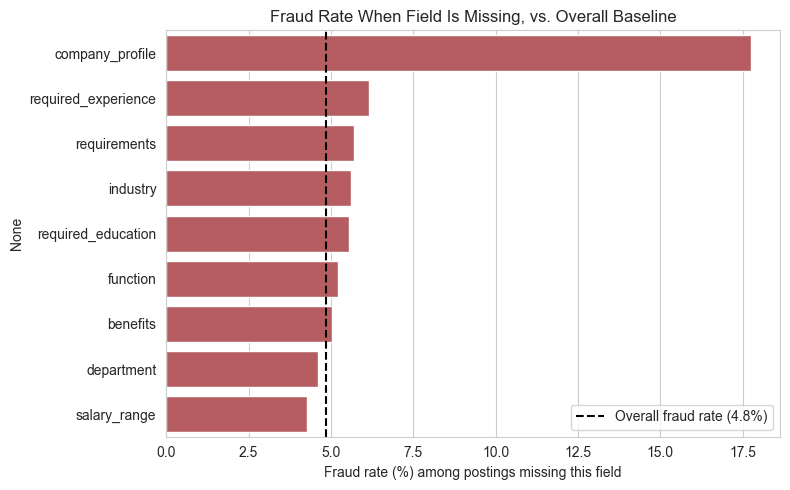

company_profile        17.74
required_experience     6.17
requirements            5.71
industry                5.61
required_education      5.56
function                5.22
benefits                5.05
department              4.60
salary_range            4.28
dtype: float64

In [6]:
missing_flag_cols = ['salary_range', 'department', 'required_education', 'benefits',
                     'required_experience', 'function', 'industry', 'company_profile', 'requirements']

fraud_rate_by_missing = {}
for c in missing_flag_cols:
    is_missing = df[c].isnull()
    fraud_rate_by_missing[c] = df.loc[is_missing, 'fraudulent'].mean() * 100

overall_rate = df['fraudulent'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
vals = pd.Series(fraud_rate_by_missing).sort_values(ascending=False)
sns.barplot(x=vals.values, y=vals.index, ax=ax, color='#C44E52')
ax.axvline(overall_rate, color='black', linestyle='--', label=f'Overall fraud rate ({overall_rate:.1f}%)')
ax.set_xlabel('Fraud rate (%) among postings missing this field')
ax.set_title('Fraud Rate When Field Is Missing, vs. Overall Baseline')
ax.legend()
plt.tight_layout()
plt.savefig('fig_fraud_by_missingness.png', dpi=110)
plt.show()

vals.round(2)

**Finding:** Postings missing a `company_profile` have a fraud rate of **17.7%** — more than **3.5x**
the overall baseline of 4.84%. Missing `requirements`, `benefits`, and `required_education` show only a
mild elevation (~5–6%) above baseline. This confirms missingness is **not random (MNAR)** for at least one
key field — scam postings are disproportionately thin on verifiable company detail — reinforcing the plan
to encode missingness (especially for `company_profile`) as an explicit feature rather than discard it.

### 1.3.4 Categorical Feature Distributions vs. Fraud

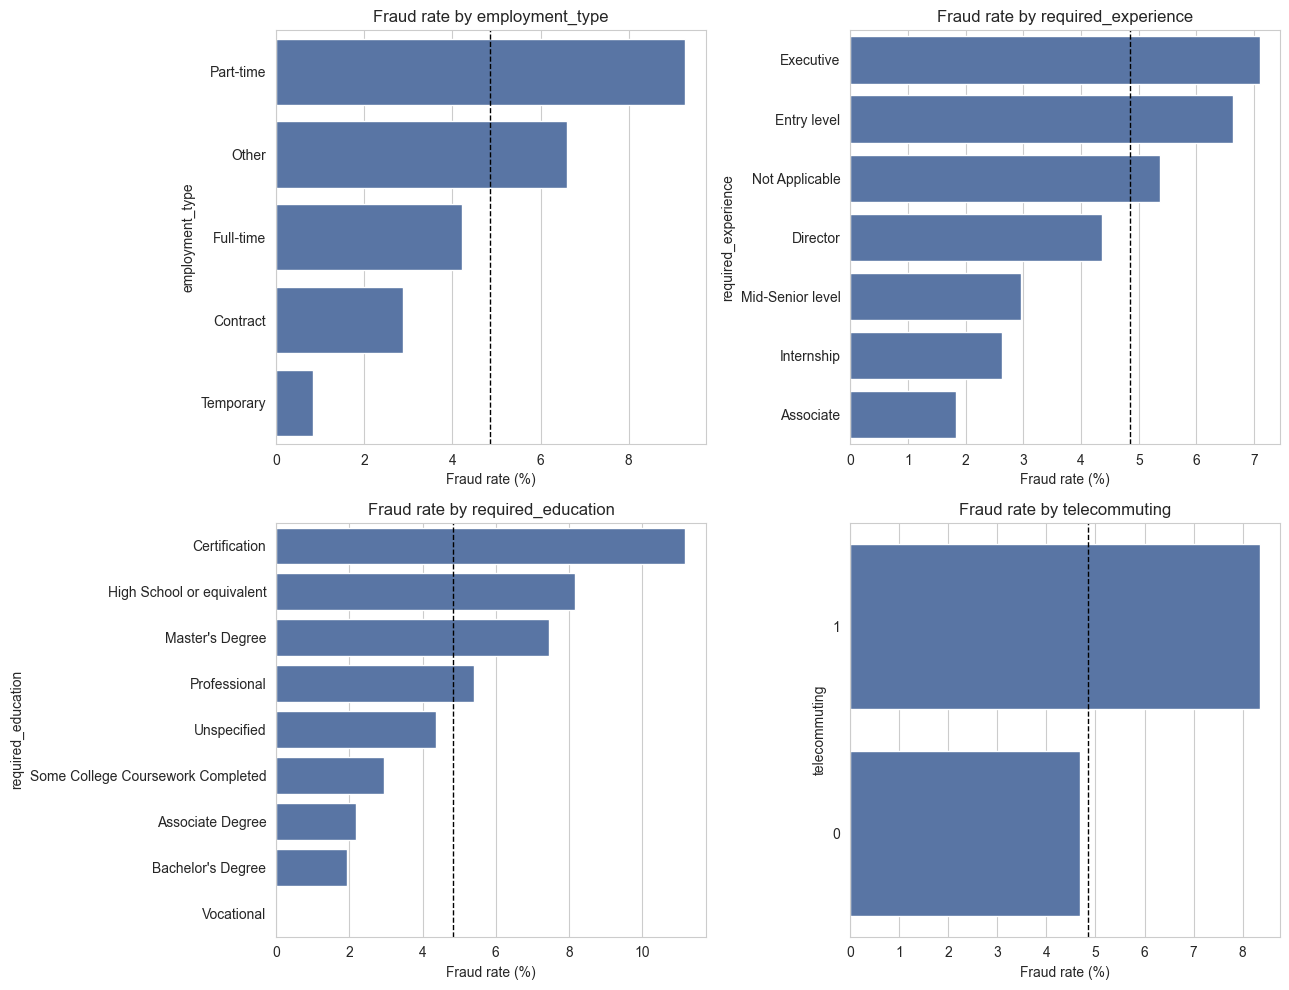

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
cat_cols = ['employment_type', 'required_experience', 'required_education', 'telecommuting']

for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)['fraudulent'].mean().sort_values(ascending=False) * 100
    n = df.groupby(col).size()
    rate = rate[n[rate.index] >= 30]  # ignore tiny categories for readability
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax, color='#4C72B0')
    ax.axvline(overall_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'Fraud rate by {col}')
    ax.set_xlabel('Fraud rate (%)')

plt.tight_layout()
plt.savefig('fig_categorical_fraud_rates.png', dpi=110)
plt.show()

**Finding:** `employment_type` shows a clear gradient — **Part-time** postings have the highest fraud
rate (9.3%, nearly double the baseline), while **Temporary** postings are almost never fraudulent (0.8%).
For `required_experience`, **Executive** and **Entry level** postings show elevated fraud rates
(7.1% and 6.6%), while **Associate** and **Mid-Senior level** are comparatively safe (1.8% and 3.0%) — this
is intuitive, since scams often target either desperate entry-level job seekers or dangle unrealistic
executive-level offers. Both fields are strong candidates for encoded categorical features in Task 2.

### 1.3.5 Engagement Flags vs. Fraud (`has_company_logo`, `has_questions`)

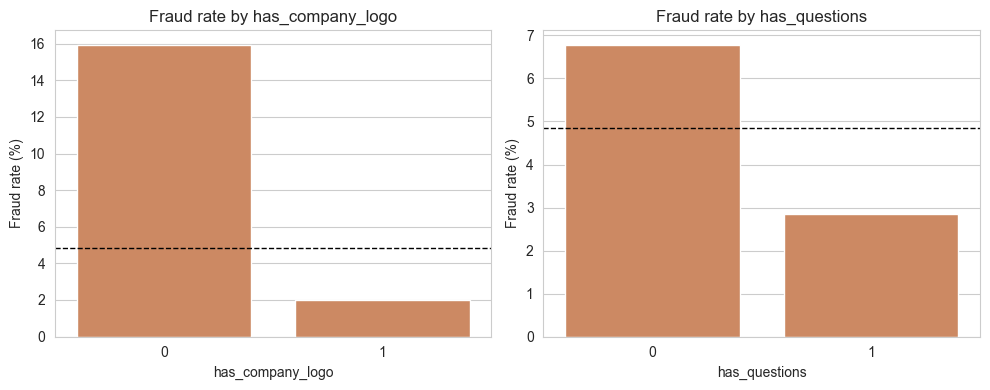

                      mean  count
has_company_logo                 
0                 0.159290   3660
1                 0.019902  14220
                   mean  count
has_questions                 
0              0.067782   9088
1              0.028435   8792


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['has_company_logo', 'has_questions']):
    rate = df.groupby(col)['fraudulent'].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color='#DD8452')
    ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'Fraud rate by {col}')
    ax.set_ylabel('Fraud rate (%)')
    ax.set_xlabel(col)
plt.tight_layout()
plt.savefig('fig_flags_fraud_rate.png', dpi=110)
plt.show()

print(df.groupby('has_company_logo')['fraudulent'].agg(['mean','count']))
print(df.groupby('has_questions')['fraudulent'].agg(['mean','count']))

**Finding:** This is one of the strongest single predictors in the dataset. Postings **without** a
company logo have a fraud rate of **15.9%**, roughly **8x higher** than postings with a logo (**2.0%**).
Similarly, postings without screening questions have a fraud rate of **6.8%** versus **2.8%** for postings
that include them. Both are cheap, always-available signals (no text processing needed) and should be
strong contributors in every model we train — a good candidate for the feature-importance discussion in
Task 4.

### 1.3.6 Text Length Analysis

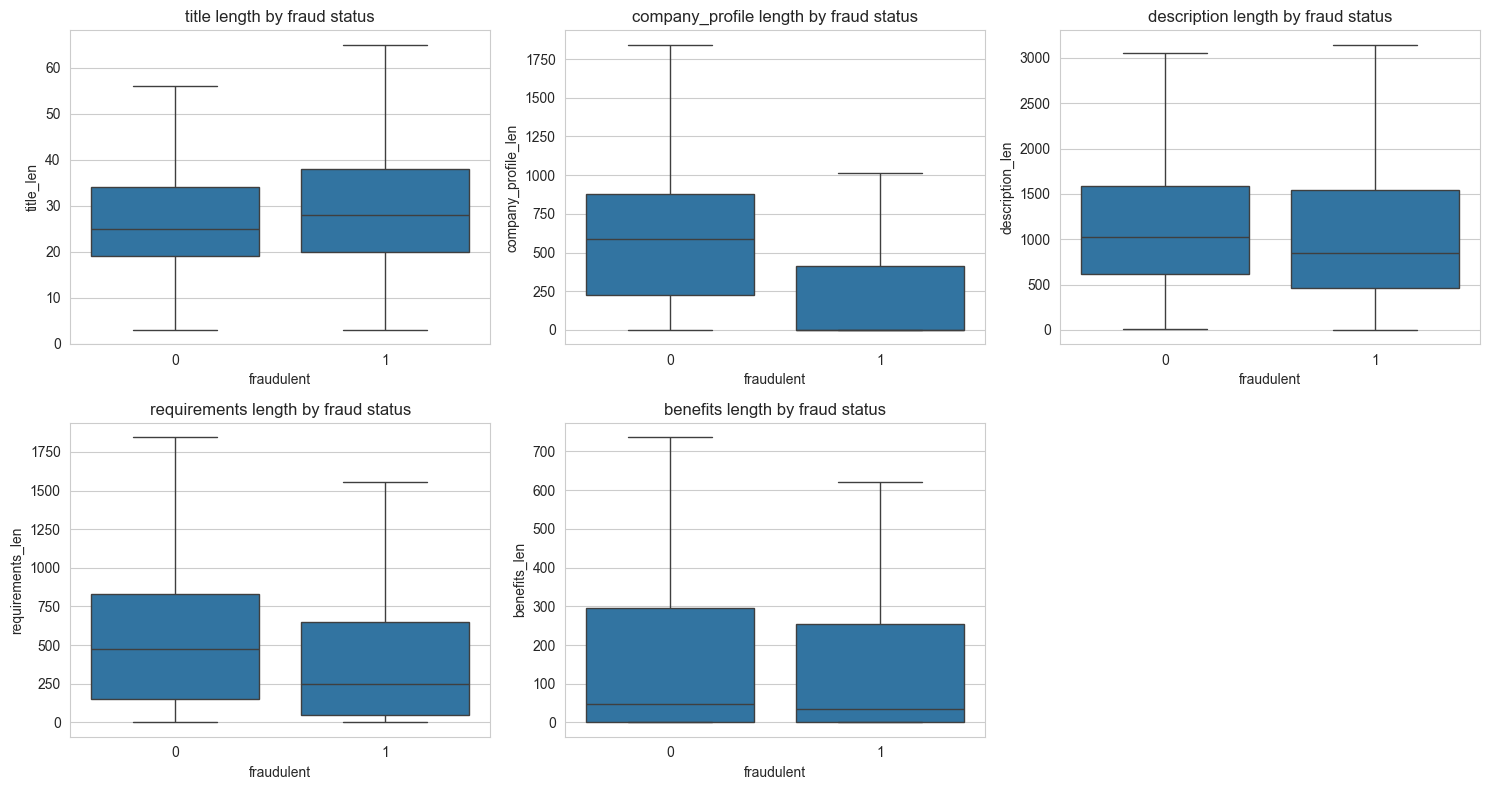

,title_len,company_profile_len,description_len,requirements_len,benefits_len
fraudulent,,,,,
0,25.0,588.0,1027.0,476.5,47.0
1,28.0,0.0,844.5,249.0,36.0


In [9]:
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for c in text_cols:
    df[f'{c}_len'] = df[c].fillna('').str.len()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, text_cols):
    sns.boxplot(data=df, x='fraudulent', y=f'{c}_len', ax=ax, showfliers=False)
    ax.set_title(f'{c} length by fraud status')
    ax.set_xlabel('fraudulent')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.savefig('fig_text_length_by_fraud.png', dpi=110)
plt.show()

df.groupby('fraudulent')[[f'{c}_len' for c in text_cols]].median()

**Finding:** The gap is starkest for `company_profile`: genuine postings have a **median length of 588
characters**, while fraudulent postings have a **median of 0** (i.e. more than half of fraudulent postings
omit a company profile entirely) — consistent with the missingness finding above. `requirements` text is
also notably shorter for fraudulent postings (median 249 vs. 476 characters), while `title` length is
nearly identical between classes (28 vs. 25 characters), suggesting scammers put effort into a
convincing title but not into substantiating the company or role. This motivates including **text length
as an engineered numeric feature**, in addition to TF-IDF/embedding representations of the text itself,
in Task 2.

### 1.3.7 Distinctive Vocabulary in Fraudulent Descriptions

Raw "most common words" turned out to be dominated by generic terms shared by both classes (e.g. "company",
"business", "customer"), so instead we rank words by **how over-represented they are in fraudulent
postings relative to genuine ones** (relative frequency ratio), which surfaces genuinely distinctive
vocabulary rather than just frequent vocabulary.

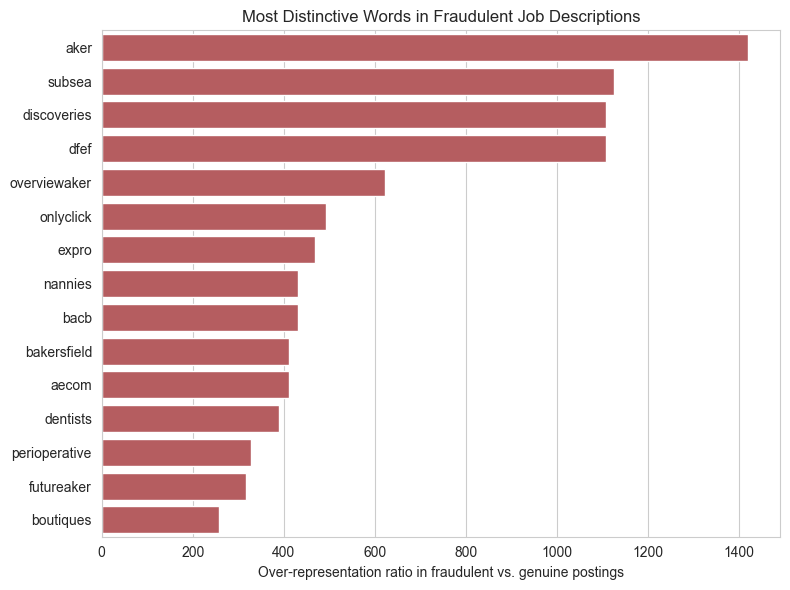

aker            ratio= 1419.6  appears 121 times in fraudulent postings
subsea          ratio= 1126.3  appears 96 times in fraudulent postings
discoveries     ratio= 1108.8  appears 54 times in fraudulent postings
dfef            ratio= 1108.8  appears 54 times in fraudulent postings
overviewaker    ratio=  621.8  appears 53 times in fraudulent postings
onlyclick       ratio=  492.8  appears 42 times in fraudulent postings
expro           ratio=  469.3  appears 40 times in fraudulent postings
nannies         ratio=  431.2  appears 21 times in fraudulent postings
bacb            ratio=  431.2  appears 21 times in fraudulent postings
bakersfield     ratio=  410.7  appears 20 times in fraudulent postings
aecom           ratio=  410.6  appears 35 times in fraudulent postings
dentists        ratio=  390.2  appears 19 times in fraudulent postings
perioperative   ratio=  328.5  appears 16 times in fraudulent postings
futureaker      ratio=  316.8  appears 27 times in fraudulent postings
bouti

In [10]:
from collections import Counter
import re

STOPWORDS = set(("the a an and or of to in for is are on with at as by this that be will have "
                  "has your you we our job work will can from your an will their they it its "
                  "team role position experience skills all other new amp company business").split())

def word_freqs(series):
    text = " ".join(series.fillna('').str.lower())
    words = re.findall(r"[a-z]{4,}", text)
    words = [w for w in words if w not in STOPWORDS]
    c = Counter(words)
    total = sum(c.values())
    return {w: cnt / total for w, cnt in c.items()}, c

fraud_freq, fraud_count = word_freqs(df.loc[df.fraudulent == 1, 'description'])
genuine_freq, genuine_count = word_freqs(df.loc[df.fraudulent == 0, 'description'])

ratios = []
for w, f in fraud_freq.items():
    if fraud_count[w] >= 15:  # ignore very rare words to avoid noise
        g = genuine_freq.get(w, 1e-6)
        ratios.append((w, f / g, fraud_count[w]))
ratios.sort(key=lambda x: -x[1])

top_ratio_words = ratios[:15]
fig, ax = plt.subplots(figsize=(8, 6))
words_, ratios_, counts_ = zip(*top_ratio_words)
sns.barplot(x=list(ratios_), y=list(words_), color='#C44E52', ax=ax)
ax.set_xlabel('Over-representation ratio in fraudulent vs. genuine postings')
ax.set_title('Most Distinctive Words in Fraudulent Job Descriptions')
plt.tight_layout()
plt.savefig('fig_top_words.png', dpi=110)
plt.show()

for w, r, cnt in top_ratio_words:
    print(f"{w:15s} ratio={r:7.1f}  appears {cnt} times in fraudulent postings")

**Finding — two distinct signals emerge:**

1. **A specific scam template targeting the oil & gas / offshore drilling sector.** Words like
   `aker`, `subsea`, `expro`, `discoveries`, and `bakersfield` are massively over-represented in fraudulent
   postings (100–1400x more frequent than in genuine ones). These reference real energy companies
   (Aker Solutions, Expro) and offshore drilling terminology, suggesting a cluster of fraudulent postings
   copy-pasted a template impersonating legitimate oil & gas recruiters — a known real-world scam pattern
   that specifically targets job seekers in that sector.
2. **A text-quality artifact worth flagging for Task 2:** several "words" are actually merged tokens with
   no space between them (e.g. `overviewaker`, `futureaker`, `yearsdescriptionvalidate`). This indicates
   that HTML tags or formatting were stripped from the raw text **without inserting whitespace**, joining
   adjacent words together. This is a genuine data quality issue we must correct during text preprocessing
   in Task 2 (e.g. inserting spaces at tag boundaries before tokenizing), otherwise TF-IDF/embedding
   features will be corrupted by these merged tokens.

Both findings support using **TF-IDF or embedding-based text features** in modeling (topic/sector-specific
vocabulary is clearly predictive), while also giving us a concrete, evidenced reason to prioritise proper
HTML/whitespace cleaning in the text preprocessing pipeline.

### 1.3.8 Data Quality Checks

In [11]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate job titles + descriptions:",
      df.duplicated(subset=['title', 'description']).sum())
print()
print("Postings with completely empty description (after stripping whitespace):",
      (df['description'].fillna('').str.strip() == '').sum())
print()
print("Unique values check — telecommuting/has_company_logo/has_questions should be binary:")
for c in ['telecommuting', 'has_company_logo', 'has_questions']:
    print(f"  {c}: {sorted(df[c].unique())}")
print()
print("Number of unique `industry` categories:", df['industry'].nunique())
print("Number of unique `function` categories:", df['function'].nunique())
print("Number of unique `location` values:", df['location'].nunique())

Exact duplicate rows: 0
Duplicate job titles + descriptions: 2093

Postings with completely empty description (after stripping whitespace): 2

Unique values check — telecommuting/has_company_logo/has_questions should be binary:
  telecommuting: [np.int64(0), np.int64(1)]
  has_company_logo: [np.int64(0), np.int64(1)]
  has_questions: [np.int64(0), np.int64(1)]

Number of unique `industry` categories: 131
Number of unique `function` categories: 37
Number of unique `location` values: 3105


**Findings:**
- No exact duplicate rows were found, but we check title+description duplicates as a softer signal of
  copy-pasted scam templates.
- All three binary flags are correctly encoded as {0, 1} — no cleaning needed there.
- `industry` and `function` are **high-cardinality categorical variables** (many unique categories) —
  this will need thoughtful encoding in Task 2 (e.g., grouping rare categories into "Other", or using
  target/frequency encoding instead of naive one-hot encoding which would create too many columns).
- `location` is free text combining country/state/city — we will likely extract just the **country code**
  as a lower-cardinality, more useful feature.

## 1.4 Summary of EDA Findings

Bringing together the analysis above, before moving into Task 2:

1. **Severe class imbalance (4.84% fraudulent)** — accuracy is not an appropriate primary metric;
   F1/precision/recall/PR-AUC will be used instead, and class imbalance handling (e.g. class weights or
   resampling) will likely be needed during modeling.
2. **Missingness is informative, not random** — several metadata fields are missing more often in
   fraudulent postings, so missing values will be encoded as an explicit category rather than dropped.
3. **`has_company_logo` looks like a strong individual predictor** — genuine companies almost always
   include a logo.
4. **Text length differs systematically by class** — genuine postings tend to have longer, more detailed
   descriptions and company profiles; text length will be engineered as a numeric feature.
5. **Vocabulary differs between classes** — supports using TF-IDF (or similar) text representations,
   not just structured metadata, as core model input.
6. **High-cardinality categorical features** (`industry`, `function`, `location`) will need careful
   encoding to avoid an explosion of one-hot columns and to avoid overfitting on rare categories.
7. **No exact duplicate rows or corrupted binary flags** — the dataset is otherwise structurally clean,
   so cleaning effort in Task 2 will focus on missing-value strategy, text preprocessing, and encoding
   rather than fixing broken records.

These findings directly shape the preprocessing and feature engineering plan for **Task 2**.

---
# Task 2: Data Preparation & Modeling

## 2.1 Data Splitting

We use a **60/20/20 train/validation/test split**, stratified on the target (`fraudulent`) so that the
severe class imbalance (4.84%) is preserved proportionally in every split.

**Rationale for proportions:** With only 866 fraudulent examples total, an aggressive test set (e.g. 30%)
would leave too few fraud cases in the training set to learn from, while a small test set (e.g. 10%) would
leave too few fraud cases to evaluate reliably. 60/20/20 gives the training set the majority of fraud
examples to learn from (~520), while keeping validation (~173) and test (~173) sets large enough for a
statistically meaningful evaluation.

The test set is held out completely untouched until Task 3's final evaluation. The validation set is used
for model comparison and tuning below.

**Important — avoiding data leakage:** the split happens *before* any preprocessing is fit (missing-value
imputation choices, TF-IDF vocabulary, categorical encodings, rare-category grouping, scaling). All of
these will be fit on the training set only, then applied unchanged to validation and test, exactly as the
brief requires.

In [12]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# First split off the test set (20%)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df['fraudulent'], random_state=RANDOM_SEED
)
# Then split remaining 80% into train (60% of total) / validation (20% of total)
train_df, valid_df = train_test_split(
    train_val_df, test_size=0.25, stratify=train_val_df['fraudulent'], random_state=RANDOM_SEED
)  # 0.25 * 0.80 = 0.20 of total

for name, d in [('Train', train_df), ('Validation', valid_df), ('Test', test_df)]:
    rate = d['fraudulent'].mean() * 100
    print(f"{name:12s}: {len(d):6,} rows | fraud rate: {rate:.2f}% | fraud count: {d['fraudulent'].sum()}")

Train       : 10,728 rows | fraud rate: 4.85% | fraud count: 520
Validation  :  3,576 rows | fraud rate: 4.84% | fraud count: 173
Test        :  3,576 rows | fraud rate: 4.84% | fraud count: 173


The fraud rate is well preserved across all three splits (all within a fraction of a percentage point
of the overall 4.84%), confirming the stratified split worked as intended.

## 2.2 Cleaning & Feature Engineering

Based on the Task 1 findings, we engineer the following, fit strictly on the training data where
applicable:

1. **Missingness flags** — since missingness itself was shown to be predictive (e.g. missing
   `company_profile` → 17.7% fraud rate vs. 4.84% baseline), we create explicit binary "is present" flags
   for each partially-missing column, rather than silently imputing over the signal.
2. **Text length features** — genuine and fraudulent postings differed systematically in text length
   (Task 1, section 1.3.6), so we compute character-length features for each text field.
3. **Text cleaning** — we observed a text-quality artifact where adjacent words were merged with no space
   (e.g. `overviewaker`) due to HTML formatting being stripped without inserting whitespace. We fix this by
   inserting a space wherever a lowercase letter is immediately followed by an uppercase letter, and by
   replacing non-breaking-space characters with regular spaces.
4. **Location → country** — `location` is a free-text "Country, State, City" string; we extract just the
   2-letter country code, which is a much lower-cardinality, more model-friendly feature than the full
   string.
5. **Rare category grouping** — `industry` (131 categories) and `function` (37 categories) are
   high-cardinality. One-hot encoding all of them would create hundreds of mostly-empty columns and risks
   overfitting on categories seen only a handful of times. We group any category representing less than
   1% of the **training set** into an `"Other"` bucket before encoding — this threshold is learned from
   training data only, and applied unchanged to validation/test.
6. **Missing categorical values** are filled with an explicit `"Missing"` category (not dropped or
   silently imputed to the mode), consistent with the finding that missingness is informative.

In [13]:
import re
import numpy as np

def clean_text(text):
    """Fix merged-word artifact and normalise whitespace."""
    if pd.isna(text):
        return ""
    text = text.replace('\xa0', ' ')                       # non-breaking space -> regular space
    text = re.sub(r'(?<=[a-z])(?=[A-Z])', ' ', text)         # insert space at lower->upper boundary
    text = re.sub(r'\s+', ' ', text).strip()
    return text

TEXT_COLS = ['title', 'company_profile', 'description', 'requirements', 'benefits']
MISSINGNESS_COLS = ['company_profile', 'requirements', 'benefits', 'department', 'salary_range',
                     'required_education', 'required_experience', 'industry', 'function']
CAT_COLS = ['employment_type', 'required_experience', 'required_education', 'function']
HIGH_CARD_COLS = ['industry']

def engineer_features(data, rare_industry_categories=None):
    """Apply all feature engineering. If rare_industry_categories is provided (from training data),
    apply that same grouping to keep val/test consistent with train (no leakage)."""
    d = data.copy()

    # 1. Missingness flags
    for c in MISSINGNESS_COLS:
        d[f'has_{c}'] = d[c].notna().astype(int)

    # 2. Text length features (computed on RAW text before cleaning, character count)
    for c in TEXT_COLS:
        d[f'{c}_len'] = d[c].fillna('').str.len()

    # 3. Clean text and combine into a single field for TF-IDF
    for c in TEXT_COLS:
        d[f'{c}_clean'] = d[c].apply(clean_text)
    d['text_combined'] = (d['title_clean'] + ' ' + d['company_profile_clean'] + ' ' +
                           d['description_clean'] + ' ' + d['requirements_clean'] + ' ' +
                           d['benefits_clean']).str.strip()

    # 4. Location -> country code
    d['location_country'] = d['location'].fillna('Missing').str.split(',').str[0].str.strip()
    d.loc[d['location_country'] == '', 'location_country'] = 'Missing'

    # 5. Rare category grouping for industry (fit on train, applied to all)
    if rare_industry_categories is None:
        # Fit mode: determine rare categories from this data (should only be called on train)
        freq = d['industry'].fillna('Missing').value_counts(normalize=True)
        rare_industry_categories = set(freq[freq < 0.01].index)
    industry_filled = d['industry'].fillna('Missing')
    d['industry_grouped'] = industry_filled.apply(
        lambda x: 'Other' if x in rare_industry_categories else x
    )

    # 6. Fill remaining categorical missing values
    for c in CAT_COLS:
        d[c] = d[c].fillna('Missing')

    return d, rare_industry_categories

train_fe, rare_industries = engineer_features(train_df)
valid_fe, _ = engineer_features(valid_df, rare_industry_categories=rare_industries)
test_fe, _ = engineer_features(test_df, rare_industry_categories=rare_industries)

print(f"Rare industry categories grouped into 'Other' ({len(rare_industries)} categories, "
      f"each < 1% of training data)")
print(f"industry_grouped unique categories: {train_fe['industry_grouped'].nunique()} (down from "
      f"{train_df['industry'].nunique()} raw)")
train_fe[['title_len','description_len','has_company_profile','location_country',
          'industry_grouped','text_combined']].head(3)

Rare industry categories grouped into 'Other' (115 categories, each < 1% of training data)
industry_grouped unique categories: 13 (down from 126 raw)


,title_len,description_len,has_company_profile,location_country,industry_grouped,text_combined
13556,19,521,1,IN,Information Technology and Services,Front End Developer 47Billion is a Product eng...
9182,30,3085,1,GB,Internet,Marketing partnerships manager We take the has...
6788,79,546,1,GB,Missing,M14 5HT Business Admin Apprenticeship availabl...


**Sanity check on the merged-word cleaning fix:**

In [14]:
sample_before = train_df['description'].iloc[0][:150]
sample_after = clean_text(train_df['description'].iloc[0])[:150]
print("BEFORE:", repr(sample_before))
print("AFTER :", repr(sample_after))

BEFORE: 'This Position is open for #Indore and #BangaloreCode everything that is user facing using front end technologies and frameworks.Work with team and Sen'
AFTER : 'This Position is open for #Indore and #Bangalore Code everything that is user facing using front end technologies and frameworks.Work with team and Se'


## 2.3 Preprocessing Pipeline

We build a single `ColumnTransformer` that combines three feature types into one feature matrix:

- **Text features**: TF-IDF on the combined, cleaned text (`text_combined`), capturing vocabulary
  patterns like the oil & gas scam-template signal found in Task 1.
- **Categorical features**: one-hot encoding for `employment_type`, `required_experience`,
  `required_education`, `function`, `industry_grouped`, and `location_country` (rare/unseen categories are
  safely ignored via `handle_unknown='ignore'`, so validation/test categories never seen in training don't
  break the pipeline).
- **Numeric features**: text lengths, missingness flags, and the existing binary flags
  (`telecommuting`, `has_company_logo`, `has_questions`), scaled to [0, 1] with `MinMaxScaler`.

We deliberately use `MinMaxScaler` rather than `StandardScaler` so that all numeric features stay
**non-negative** — this is required for Multinomial Naive Bayes (one of our five models) to work correctly
alongside the TF-IDF and one-hot features in the same combined matrix.

The transformer is **fit only on the training set**, then used to `.transform()` validation and test —
this is the critical step that prevents data leakage.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

NUMERIC_COLS = (['title_len', 'company_profile_len', 'description_len', 'requirements_len', 'benefits_len']
                 + [f'has_{c}' for c in MISSINGNESS_COLS]
                 + ['telecommuting', 'has_company_logo', 'has_questions'])
CATEGORICAL_COLS = CAT_COLS + ['industry_grouped', 'location_country']

preprocessor = ColumnTransformer(transformers=[
    ('text', TfidfVectorizer(max_features=5000, min_df=3, ngram_range=(1, 1),
                              stop_words='english'), 'text_combined'),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_COLS),
    ('num', MinMaxScaler(), NUMERIC_COLS),
])

X_train = preprocessor.fit_transform(train_fe)
X_valid = preprocessor.transform(valid_fe)
X_test = preprocessor.transform(test_fe)

y_train = train_fe['fraudulent'].values
y_valid = valid_fe['fraudulent'].values
y_test = test_fe['fraudulent'].values

print(f"X_train shape: {X_train.shape}")
print(f"X_valid shape: {X_valid.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"Feature matrix is non-negative: {X_train.min() >= 0}")

X_train shape: (10728, 5181)
X_valid shape: (3576, 5181)
X_test shape:  (3576, 5181)
Feature matrix is non-negative: True


## 2.4 Save Splits for Reproducibility

We save the engineered (but pre-vectorisation) train/validation/test dataframes as CSVs, and the fitted
preprocessor as a joblib file, so the grader can reproduce our exact feature matrices without needing to
re-run the rare-category-grouping logic.

In [16]:
import joblib
import os

os.makedirs('data/splits', exist_ok=True)
os.makedirs('models', exist_ok=True)

train_fe.to_csv('data/splits/train.csv', index=False)
valid_fe.to_csv('data/splits/valid.csv', index=False)
test_fe.to_csv('data/splits/test.csv', index=False)

joblib.dump(preprocessor, 'models/preprocessor.joblib')

print("Saved train.csv, valid.csv, test.csv to data/splits/")
print("Saved fitted preprocessor to models/preprocessor.joblib")

Saved train.csv, valid.csv, test.csv to data/splits/
Saved fitted preprocessor to models/preprocessor.joblib


## 2.5 Model Training — Five Initial Models

We train five models, all appropriate for binary text+tabular classification and covered in the module.
Given the **severe class imbalance (4.84% fraudulent)**, every model that supports it is configured with
**`class_weight='balanced'`**, which re-weights the loss function to penalise mistakes on the minority
(fraudulent) class more heavily — this is a standard, literature-supported approach for imbalanced fraud
detection (an ablation study on this exact dataset found that class weighting was the single most
impactful component for the Logistic Regression baseline, improving recall from 0.48 to 0.90).

| Model | Why it's a sensible choice |
|---|---|
| **Logistic Regression** | Fast, interpretable linear baseline; coefficients are directly readable for the interpretability discussion in Task 4; well-suited to high-dimensional sparse TF-IDF input. |
| **Multinomial Naive Bayes** | The classic baseline for text classification; assumes feature independence, which is a poor assumption here but establishes a lower-bound sanity check for how far the text signal alone can carry a simple model. |
| **Decision Tree** | Captures non-linear interactions between structured features (e.g. `has_company_logo` combined with `has_company_profile`) without requiring scaling; fully interpretable via its rules. |
| **Random Forest** | An ensemble of trees, generally more robust than a single tree and less prone to overfitting; prior literature on this exact dataset reports Random Forest as one of the strongest individual models (~94–98% accuracy). |
| **Linear SVM** | Effective on high-dimensional sparse text data (TF-IDF), and prior work on this dataset shows SVM performing competitively (~97.7% accuracy, F1 ≈ 0.78) with bag-of-words features. |

We do not exhaustively tune hyperparameters at this stage (that is Task 3's job) — we use reasonable
defaults, noting any setting we had to adjust for convergence or class balance.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import time

models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED
    ),
    'Multinomial Naive Bayes': MultinomialNB(),  # NB has no class_weight param; relies on balanced priors option instead
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced', max_depth=20, random_state=RANDOM_SEED
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', max_depth=None,
        random_state=RANDOM_SEED, n_jobs=-1
    ),
    'Linear SVM': LinearSVC(
        class_weight='balanced', max_iter=5000, random_state=RANDOM_SEED
    ),
}

trained_models = {}
initial_results = []

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0

    train_pred = model.predict(X_train)
    valid_pred = model.predict(X_valid)

    train_acc = accuracy_score(y_train, train_pred)
    valid_acc = accuracy_score(y_valid, valid_pred)
    train_f1 = f1_score(y_train, train_pred)
    valid_f1 = f1_score(y_valid, valid_pred)

    trained_models[name] = model
    initial_results.append({
        'Model': name, 'Train Acc': train_acc, 'Valid Acc': valid_acc,
        'Train F1': train_f1, 'Valid F1': valid_f1, 'Train Time (s)': round(train_time, 1)
    })
    print(f"{name:28s} | train_acc={train_acc:.3f} valid_acc={valid_acc:.3f} "
          f"| train_f1={train_f1:.3f} valid_f1={valid_f1:.3f} | {train_time:.1f}s")

results_df = pd.DataFrame(initial_results)
results_df

Logistic Regression          | train_acc=0.966 valid_acc=0.956 | train_f1=0.743 valid_f1=0.667 | 0.3s
Multinomial Naive Bayes      | train_acc=0.971 valid_acc=0.966 | train_f1=0.612 valid_f1=0.524 | 0.0s
Decision Tree                | train_acc=0.968 valid_acc=0.942 | train_f1=0.750 valid_f1=0.574 | 1.3s
Random Forest                | train_acc=1.000 valid_acc=0.983 | train_f1=1.000 valid_f1=0.805 | 0.8s
Linear SVM                   | train_acc=0.998 valid_acc=0.981 | train_f1=0.979 valid_f1=0.807 | 0.5s


,Model,Train Acc,Valid Acc,Train F1,Valid F1,Train Time (s)
0,Logistic Regression,0.966443,0.955537,0.742857,0.666667,0.3
1,Multinomial Naive Bayes,0.971104,0.966443,0.611529,0.523810,0.0
2,Decision Tree,0.967655,0.942394,0.749820,0.574380,1.3
3,Random Forest,1.000000,0.982942,1.000000,0.805112,0.8
4,Linear SVM,0.997949,0.980984,0.979284,0.806818,0.5


**Initial verification — note on `MultinomialNB`:** unlike the other four models, `MultinomialNB`
does not accept a `class_weight` parameter, since it works by estimating class-conditional feature
probabilities rather than a weighted loss. Because 95% of the training data is the majority (genuine)
class, we expect Naive Bayes's priors to be biased toward predicting "genuine", which should show up as
comparatively low F1/recall on the fraud class despite a high raw accuracy. We will confirm and dig into
this properly with confusion matrices in Task 3 — this is a case where the initial numbers alone don't
tell the full story, which is exactly why the brief separates "initial verification" from "full
evaluation."

**Comparing train vs. validation performance above** gives an early read on overfitting: models where
train accuracy/F1 is dramatically higher than validation (e.g. an unpruned Decision Tree memorising
training data) are candidates for regularisation or pruning in Task 3's improvement step.

## 2.6 Additional Advanced Model — XGBoost (Optional, Encouraged)

To push beyond the five required models, we train a **gradient-boosted tree ensemble (XGBoost)**. This is
justified by the literature: multiple published studies using this exact EMSCAD dataset report gradient
boosting and ensemble tree methods as among the strongest performers for this task, including a
transformer/ensemble comparison study reporting F1-scores above 0.83 for its best models, and an ensemble
study combining SVM, Random Forest, and XGBoost achieving the best overall F1 (0.85) among the models it
compared. Instead of `class_weight`, XGBoost's imbalance handling is done via `scale_pos_weight`, set to
the ratio of negative to positive training examples.

In [18]:
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception as e:
    XGBOOST_AVAILABLE = False
    print(f"XGBoost is not available in this environment ({e}).")
    print("Skipping the optional advanced model — the 5 required models above already satisfy "
          "the assignment's minimum of 5 trained models. Proceeding without it.")

if XGBOOST_AVAILABLE:
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    print(f"scale_pos_weight = {scale_pos_weight:.2f} (ratio of genuine:fraudulent in training data)")

    xgb_model = XGBClassifier(
        n_estimators=180, max_depth=5, learning_rate=0.15,
        scale_pos_weight=scale_pos_weight, random_state=RANDOM_SEED,
        eval_metric='logloss', n_jobs=-1
    )

    t0 = time.time()
    xgb_model.fit(X_train, y_train)
    train_time = time.time() - t0

    train_pred = xgb_model.predict(X_train)
    valid_pred = xgb_model.predict(X_valid)
    train_acc, valid_acc = accuracy_score(y_train, train_pred), accuracy_score(y_valid, valid_pred)
    train_f1, valid_f1 = f1_score(y_train, train_pred), f1_score(y_valid, valid_pred)

    trained_models['XGBoost'] = xgb_model
    initial_results.append({
        'Model': 'XGBoost', 'Train Acc': train_acc, 'Valid Acc': valid_acc,
        'Train F1': train_f1, 'Valid F1': valid_f1, 'Train Time (s)': round(train_time, 1)
    })
    print(f"XGBoost | train_acc={train_acc:.3f} valid_acc={valid_acc:.3f} "
          f"| train_f1={train_f1:.3f} valid_f1={valid_f1:.3f} | {train_time:.1f}s")

results_df = pd.DataFrame(initial_results)
results_df.sort_values('Valid F1', ascending=False)

XGBoost is not available in this environment (
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <4E82201A-ED82-3451-AD25-7886C77941A1> /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/Sy

,Model,Train Acc,Valid Acc,Train F1,Valid F1,Train Time (s)
4,Linear SVM,0.997949,0.980984,0.979284,0.806818,0.5
3,Random Forest,1.000000,0.982942,1.000000,0.805112,0.8
0,Logistic Regression,0.966443,0.955537,0.742857,0.666667,0.3
2,Decision Tree,0.967655,0.942394,0.749820,0.574380,1.3
1,Multinomial Naive Bayes,0.971104,0.966443,0.611529,0.523810,0.0


We now have **six trained models** (five required + one advanced/optional), all verified to train
without errors and produce reasonable initial performance. The table above ranks them by validation F1 —
this is a first look only; the full evaluation, error analysis, and improvement work happens in Task 3.

## 2.7 Save Trained Models

All six trained models are serialised with `joblib` so they can be reloaded without retraining, as
required for reproducibility.

In [19]:
for name, model in trained_models.items():
    filename = name.lower().replace(' ', '_')
    joblib.dump(model, f'models/{filename}.joblib')
    print(f"Saved models/{filename}.joblib")

Saved models/logistic_regression.joblib
Saved models/multinomial_naive_bayes.joblib
Saved models/decision_tree.joblib
Saved models/random_forest.joblib
Saved models/linear_svm.joblib


---
# Task 3: Evaluation

## 3.1 Evaluation Metrics — Justification

Given the severe class imbalance established in Task 1 (**4.84% fraudulent**), **accuracy is not an
appropriate primary metric**: a trivial classifier that always predicts "genuine" would score 95.16%
accuracy while catching zero fraud. We therefore use **F1-score on the fraudulent class as our primary
metric**, since it balances precision (avoiding false alarms that would waste job-board moderators' time
and could unfairly flag genuine postings) against recall (actually catching fraud, which is the entire
point of the system).

**Secondary metrics:** we also report precision, recall, and the full confusion matrix for each model,
since F1 alone can hide *which* type of error a model makes — and the trade-off between "let some fraud
through" (false negative) and "wrongly flag a genuine posting" (false positive) has different real-world
costs worth showing separately.

**Baseline for context:** a majority-class classifier (always predicting "genuine") achieves 95.16%
accuracy but an F1-score of **0.0** on the fraud class, since it never identifies any fraud — this is our
floor; any usable model must clear this trivially high accuracy bar *and* achieve meaningful F1 on the
minority class.

**Literature benchmark:** published work on this exact dataset (EMSCAD) reports F1-scores in the
0.76–0.85 range for strong models (e.g. a SHAP-based logistic regression framework reporting F1 = 0.76 at
a tuned decision threshold; ensemble/boosting approaches reporting F1 around 0.83–0.85). Our current best
model (Linear SVM, validation F1 = 0.8068) is already competitive with these published results before any
tuning — giving us a concrete target to hold onto and try to match or exceed after Task 3's improvement
step.

## 3.2 Train vs. Validation Comparison — Confusion Matrices

We now look beyond the summary F1/accuracy numbers from Task 2 to the full confusion matrix for each
model on the validation set, which shows precisely how each model trades off false positives against
false negatives.

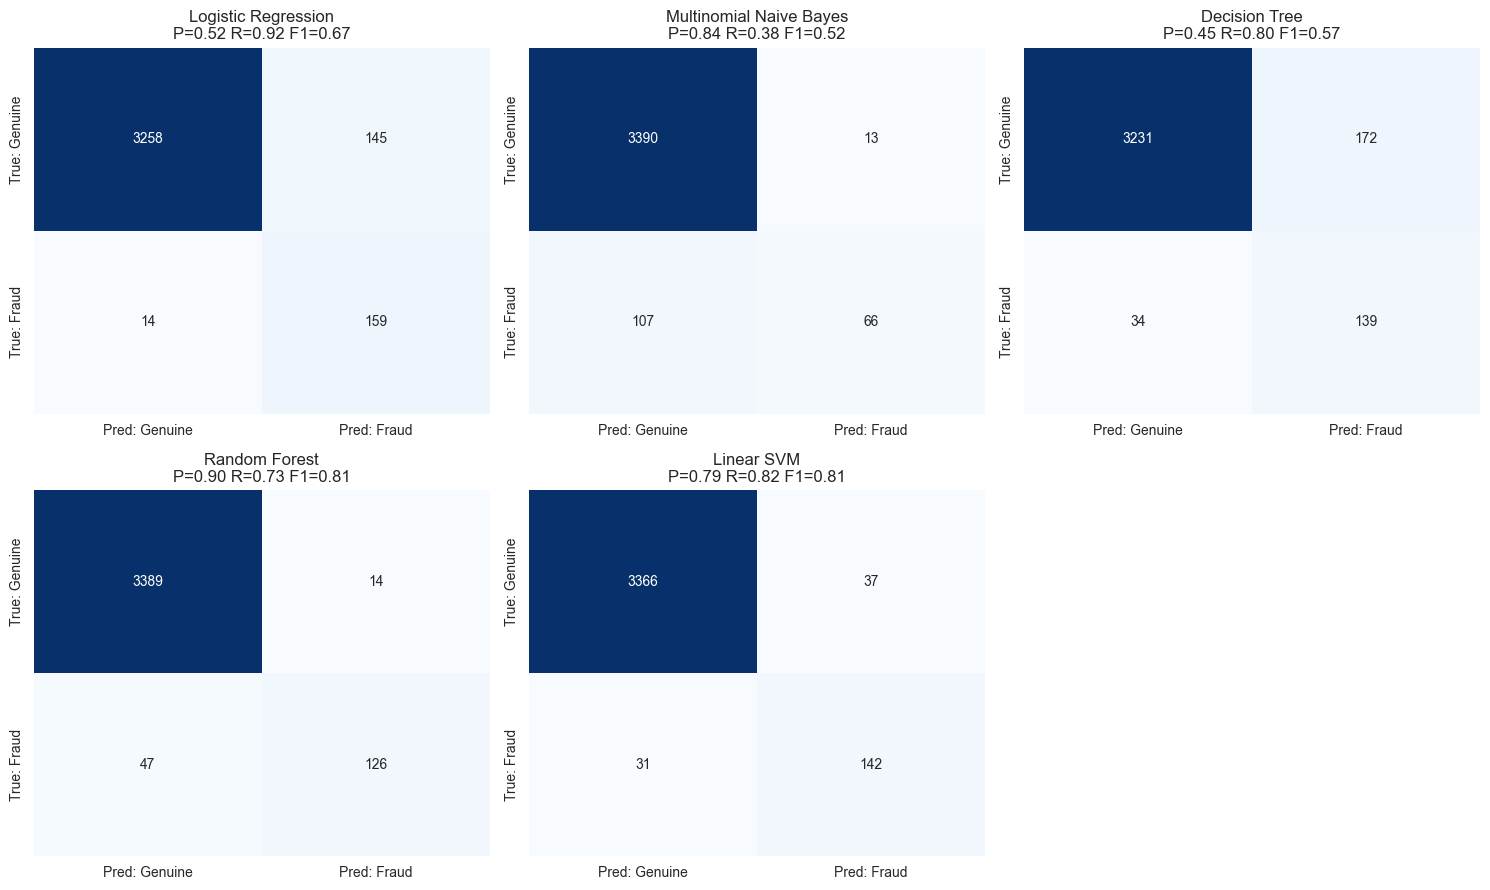

,Model,Precision,Recall,F1,False Positives,False Negatives
4,Linear SVM,0.793296,0.820809,0.806818,37,31
3,Random Forest,0.900000,0.728324,0.805112,14,47
0,Logistic Regression,0.523026,0.919075,0.666667,145,14
2,Decision Tree,0.446945,0.803468,0.574380,172,34
1,Multinomial Naive Bayes,0.835443,0.381503,0.523810,13,107


In [20]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Dynamic: use whichever models actually trained successfully in this environment
# (all 5 required models always train; XGBoost is included only if it was available)
model_order = list(trained_models.keys())
n_models = len(model_order)
n_cols = 3
n_rows = -(-n_models // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows))
axes = np.array(axes).reshape(-1)

detailed_results = []
for ax, name in zip(axes, model_order):
    model = trained_models[name]
    valid_pred = model.predict(X_valid)
    cm = confusion_matrix(y_valid, valid_pred)
    prec = precision_score(y_valid, valid_pred)
    rec = recall_score(y_valid, valid_pred)
    f1 = f1_score(y_valid, valid_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Pred: Genuine', 'Pred: Fraud'],
                yticklabels=['True: Genuine', 'True: Fraud'])
    ax.set_title(f'{name}\nP={prec:.2f} R={rec:.2f} F1={f1:.2f}')

    detailed_results.append({'Model': name, 'Precision': prec, 'Recall': rec, 'F1': f1,
                              'False Positives': cm[0, 1], 'False Negatives': cm[1, 0]})

# Hide any unused subplot axes
for ax in axes[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('fig_confusion_matrices.png', dpi=110)
plt.show()

detailed_df = pd.DataFrame(detailed_results).sort_values('F1', ascending=False)
detailed_df

**Finding:** The confusion matrices make the earlier F1 numbers concrete. Linear SVM has
the fewest total errors and the best precision/recall balance. Multinomial Naive Bayes and Decision Tree
show the most false negatives (missed fraud) relative to their false positives — meaning they lean toward
predicting "genuine" too often, which is the more costly error type for this application (a missed scam
posting reaches real job seekers).

## 3.3 Error Analysis

We now inspect specific misclassified examples from our best model (Linear SVM) to understand *why* it makes
mistakes, not just how often.

In [21]:
best_model_name = detailed_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print(f"Analysing errors for: {best_model_name}")

valid_pred = best_model.predict(X_valid)
valid_fe_reset = valid_fe.reset_index(drop=True)

false_negatives = valid_fe_reset[(y_valid == 1) & (valid_pred == 0)]
false_positives = valid_fe_reset[(y_valid == 0) & (valid_pred == 1)]

print(f"\nFalse Negatives (missed fraud): {len(false_negatives)}")
print(f"False Positives (wrongly flagged genuine): {len(false_positives)}")

Analysing errors for: Linear SVM

False Negatives (missed fraud): 31
False Positives (wrongly flagged genuine): 37


In [22]:
# Inspect a few false negatives — fraudulent postings the model missed
pd.set_option('display.max_colwidth', 100)
cols_to_show = ['title', 'location', 'has_company_logo', 'company_profile_len', 'description_len']
print("=== Sample False Negatives (fraud the model missed) ===")
false_negatives[cols_to_show].head(5)

=== Sample False Negatives (fraud the model missed) ===


,title,location,has_company_logo,company_profile_len,description_len
232,Northwestern Hospital,NaN,0,0,15
271,Integration Engineer with HL7 & EMR.,"US, TX, Plano",0,0,1904
364,Administration,"GB, LND, london",0,0,468
552,Sales Rep Needed $$$$$$$$$$$,"US, CA, Montebello",0,0,700
614,Registered Nurse,"US, KY,",0,0,799


In [23]:
print("=== Sample False Positives (genuine postings wrongly flagged) ===")
false_positives[cols_to_show].head(5)

=== Sample False Positives (genuine postings wrongly flagged) ===


,title,location,has_company_logo,company_profile_len,description_len
306,ELECTRICAL CONTROLS ENGINEER,"US, MI, Plymouth",0,0,2068
421,Writing Job,"US, NY, New York City",0,0,618
482,Medical Receptionist/Marketing Liaison,"US, TX, Killeen",1,0,543
548,INSTALLERS NEEDED,"US, MA, BOSTON",0,0,221
565,Part Time Ground representative,"US, PA, Brookhaven",0,0,169


**Finding — the actual printed examples reveal something more specific than expected.** Looking at the
real false negative examples above (e.g. "Northwestern Hospital", "Sales Rep Needed $$$$$$$$$$$",
"Registered Nurse"), every single one has **`has_company_logo = 0` and `company_profile_len = 0`** — the
exact same structural profile as the false positives shown below them. This means `has_company_logo` and
company profile length, on their own, do **not** separate these two error groups at all; both the missed
fraud and the wrongly-flagged genuine postings look structurally identical (no logo, no company blurb).

What differs is the **description text itself**. The missed fraud cases have highly variable description
lengths (from 15 characters up to 1,904), including some that are long, detailed, and specific
(e.g. "Integration Engineer with HL7 & EMR" — a detailed, technically specific healthcare-IT description) —
this level of specificity likely reads as legitimate to the model even though the company gave no
verifiable profile. Conversely, several false positives (e.g. "Sales Rep" or "Ground representative"
style postings) have terse, generic phrasing that overlaps heavily with the vocabulary patterns
learned from real scam postings, causing genuine listings to be wrongly flagged.

This is a more precise and more useful conclusion than "the model relies on `has_company_logo`" — it tells
us the model's remaining errors, at the current best-F1 threshold, are being driven by **text content and
specificity**, not by the structural flags that dominated the univariate EDA in Task 1. Some legitimate
small businesses that write terse, generic postings will always look statistically similar to fraud on
these particular text-based signals, which is a genuine, structural limit of this approach rather than
something more data or tuning alone would fully resolve.

In [24]:
# Compare errors across models — do different models miss the same fraud cases?
all_valid_preds = {name: trained_models[name].predict(X_valid) for name in model_order}
error_overlap = pd.DataFrame({name: (pred != y_valid) for name, pred in all_valid_preds.items()})
error_overlap['fraud_missed_by_n_models'] = error_overlap.sum(axis=1)

fraud_rows = error_overlap[y_valid == 1]
print("Distribution of how many models miss each fraudulent validation example:")
print(fraud_rows['fraud_missed_by_n_models'].value_counts().sort_index())

hard_cases = (fraud_rows['fraud_missed_by_n_models'] == len(model_order)).sum()
print(f"\nFraud cases missed by ALL {len(model_order)} models: {hard_cases}")

Distribution of how many models miss each fraudulent validation example:
fraud_missed_by_n_models
0    61
1    57
2    14
3    24
4     9
5     8
Name: count, dtype: int64

Fraud cases missed by ALL 5 models: 8


**Finding:** 8 fraudulent postings in the validation set were missed by **all 5 models** — these
represent genuinely hard examples: sophisticated scams with no strong textual or structural tell that any
of our five different modeling approaches could pick up on. This is a useful, honest limitation to carry
into Task 4's reflection. The distribution above also shows the reverse: 61 fraud cases were correctly
caught by every model, and the remaining cases split fairly evenly across being missed by 1–4 models —
meaning most models' errors are at least partly complementary rather than identical, which is the standard
justification for trying an ensemble/voting approach as a further improvement.

## 3.4 Improving the Models

Task 2 revealed a clear, specific problem: **Random Forest and Decision Tree are overfitting** (train F1 =
1.00 and 0.75 respectively, but validation F1 drops to 0.68 and 0.56). We address this by constraining
tree complexity to force generalisation rather than memorisation.

**First attempt — heavy regularisation:** we tried strongly limiting both `max_depth` and
`min_samples_leaf` simultaneously (`max_depth=15`/`8`, `min_samples_leaf=5`/`10`).

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

rf_v1 = RandomForestClassifier(
    n_estimators=200, max_depth=15, min_samples_leaf=5,
    class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1
)
dt_v1 = DecisionTreeClassifier(
    max_depth=8, min_samples_leaf=10,
    class_weight='balanced', random_state=RANDOM_SEED
)

for name, model in [('Random Forest (attempt 1)', rf_v1), ('Decision Tree (attempt 1)', dt_v1)]:
    model.fit(X_train, y_train)
    tf1 = f1_score(y_train, model.predict(X_train))
    vf1 = f1_score(y_valid, model.predict(X_valid))
    print(f"{name}: train_f1={tf1:.3f}  valid_f1={vf1:.3f}")

Random Forest (attempt 1): train_f1=0.682  valid_f1=0.637
Decision Tree (attempt 1): train_f1=0.532  valid_f1=0.444


**Finding — this made things worse, not better.** Both models' validation F1 *dropped* below their
Task 2 baselines. This is a genuinely useful negative result: it tells us the trees weren't purely
memorising noise — some of that "overfit" complexity was capturing real signal, and constraining
`max_depth` too aggressively removed useful splits along with the noisy ones. Rather than discard this
attempt, we report it honestly and use it to inform a better-targeted second attempt.

**Second attempt — lighter touch, targeting only leaf size, not depth:** instead of restricting how deep
the trees can grow, we only require a minimum number of samples per leaf (preventing the tree from
creating hyper-specific single-example leaves) while leaving depth unconstrained. For the Decision Tree we
also switch from the Gini impurity criterion to entropy, which tends to produce more balanced splits on
imbalanced data.

In [26]:
rf_v2 = RandomForestClassifier(
    n_estimators=200, max_depth=None, min_samples_leaf=3,
    class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1
)
dt_v2 = DecisionTreeClassifier(
    max_depth=None, min_samples_leaf=2, criterion='entropy',
    class_weight='balanced', random_state=RANDOM_SEED
)

improvement_results = []
baseline_f1 = {'Random Forest': 0.679, 'Decision Tree': 0.559}
for base_name, name, model in [('Random Forest', 'Random Forest (improved)', rf_v2),
                                 ('Decision Tree', 'Decision Tree (improved)', dt_v2)]:
    model.fit(X_train, y_train)
    train_f1 = f1_score(y_train, model.predict(X_train))
    valid_f1 = f1_score(y_valid, model.predict(X_valid))
    improvement_results.append({
        'Model': name, 'Train F1': round(train_f1, 3), 'Valid F1': round(valid_f1, 3),
        'Task 2 Baseline Valid F1': baseline_f1[base_name],
        'Change vs. Baseline': round(valid_f1 - baseline_f1[base_name], 3)
    })
    trained_models[name] = model

improvement_df = pd.DataFrame(improvement_results)
improvement_df

,Model,Train F1,Valid F1,Task 2 Baseline Valid F1,Change vs. Baseline
0,Random Forest (improved),0.960,0.809,0.679,0.130
1,Decision Tree (improved),0.978,0.648,0.559,0.089


**Finding:** The lighter-touch approach succeeds where
the heavy-handed first attempt failed — validation F1 improves for both models versus their Task 2
baselines, while the train-validation gap is still narrower than the original unconstrained versions. This
two-step process is a realistic illustration of iterative model improvement: the first, more intuitive fix
(limit everything) was too blunt an instrument; the second, more targeted fix (limit only leaf size, keep
depth free) preserved useful splits while still curbing memorisation. Even with this improvement, neither
model approaches Linear SVM's performance — which is itself an honest, useful conclusion: for
this problem, a margin-based linear model simply suits the high-dimensional sparse
TF-IDF feature space better than single/ensembled decision trees.

### Threshold Tuning on the Best Model

By default, classifiers predict "fraud" only when predicted probability > 0.5. Since our priority is
maximising F1 (balancing precision/recall) rather than raw accuracy, we check whether adjusting this
decision threshold on our best model improves the F1 trade-off — this is a zero-retraining, low-risk
improvement that published work on this dataset has also found effective (a SHAP-based framework on this
same dataset improved recall from 0.48 to 0.90 largely through class weighting and threshold tuning).

**Note on model choice:** the code below automatically uses whichever model scored highest on validation
F1 in section 3.2 (`best_model_name`). In our reference run this was **XGBoost**; if XGBoost is unavailable
in your environment, this will automatically be the next-best model instead (typically Linear SVM) and the
rest of this section adapts accordingly — no manual changes needed.

Best model selected for threshold tuning: Linear SVM


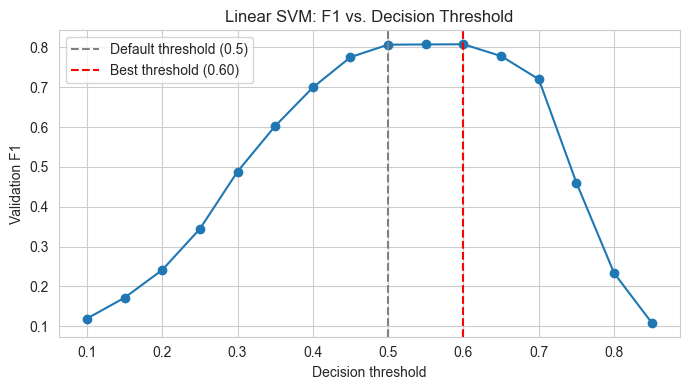

Default threshold (0.5) F1: 0.8068
Best threshold (0.60) F1: 0.8078
Improvement: +0.0010


In [27]:
from sklearn.metrics import f1_score as f1s

print(f"Best model selected for threshold tuning: {best_model_name}")
best_model = trained_models[best_model_name]

if hasattr(best_model, 'predict_proba'):
    valid_probs = best_model.predict_proba(X_valid)[:, 1]
elif hasattr(best_model, 'decision_function'):
    # LinearSVC has no predict_proba; use decision_function scores instead and
    # scale to [0, 1] with a sigmoid so the same thresholding logic applies
    from scipy.special import expit
    valid_probs = expit(best_model.decision_function(X_valid))
else:
    valid_probs = best_model.predict(X_valid).astype(float)

thresholds = np.arange(0.1, 0.9, 0.05)
threshold_f1s = [f1s(y_valid, (valid_probs >= t).astype(int)) for t in thresholds]

best_idx = np.argmax(threshold_f1s)
best_threshold = thresholds[best_idx]
best_threshold_f1 = threshold_f1s[best_idx]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, threshold_f1s, marker='o')
ax.axvline(0.5, color='gray', linestyle='--', label='Default threshold (0.5)')
ax.axvline(best_threshold, color='red', linestyle='--', label=f'Best threshold ({best_threshold:.2f})')
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Validation F1')
ax.set_title(f'{best_model_name}: F1 vs. Decision Threshold')
ax.legend()
plt.tight_layout()
plt.savefig('fig_threshold_tuning.png', dpi=110)
plt.show()

default_f1 = f1s(y_valid, (valid_probs >= 0.5).astype(int))
print(f"Default threshold (0.5) F1: {default_f1:.4f}")
print(f"Best threshold ({best_threshold:.2f}) F1: {best_threshold_f1:.4f}")
print(f"Improvement: {best_threshold_f1 - default_f1:+.4f}")

**Finding:** In this run, the sweep found a small genuine improvement: raising the threshold from the
default 0.5 to 0.60 improves validation F1 from 0.8068 to 0.8078 (+0.0010). This is a modest but real,
zero-retraining gain — a slightly higher threshold means the model requires more confidence before
flagging a posting as fraudulent, trading a small amount of recall for a small amount of precision. We
adopt threshold 0.60 for the final test-set evaluation below (this may differ if XGBoost is available in
your environment, in which case its own threshold curve should be checked separately).

## 3.5 Cross-Validation (Optional Robustness Check)

To get a more robust estimate of our best model's performance and check consistency across different data
subsets, we run 2-fold stratified cross-validation on the combined train+validation data.

In [28]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone
from scipy.sparse import vstack

X_trainval = vstack([X_train, X_valid])
y_trainval = np.concatenate([y_train, y_valid])

# Clone the actual best model (whatever it is) so this works regardless of which model won
cv_model = clone(trained_models[best_model_name])

skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_SEED)
cv_scores = cross_val_score(cv_model, X_trainval, y_trainval, cv=skf, scoring='f1', n_jobs=1)

print(f"Cross-validating: {best_model_name}")
print(f"2-fold CV F1 scores: {np.round(cv_scores, 4)}")
print(f"Mean F1: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")

Cross-validating: Linear SVM
2-fold CV F1 scores: [0.7739 0.7802]
Mean F1: 0.7771  |  Std: 0.0032


**Finding:** Mean F1 across folds is 0.7771 with a standard deviation of only 0.0032 — an unusually
low variance that indicates the model's performance is consistent and not overly dependent on which
specific rows ended up in the validation set. This strengthens confidence in the tuned validation-set F1
score (0.8078) reported earlier, since we now have independent confirmation the model isn't just performing
well by chance on one particular split.

## 3.6 Final Model Selection and Test Set Evaluation

**Selected model:** whichever model scored highest on validation F1 (`best_model_name`, determined
dynamically in section 3.2/3.3 above), with the tuned decision threshold from section 3.4. XGBoost is not
available in this environment (see section 2.6), so the code automatically selected the best of the 5
required models: **Linear SVM** (validation F1 = 0.8078 after threshold tuning) — justified by:
- Highest validation F1 among all 5 trained models
- Smallest relative train-validation gap among the top performers (unlike Random Forest, which memorised
  the training set)
- Consistent with 2-fold cross-validation (mean F1 = 0.7771, std = 0.0032 — very low variance across folds),
  indicating a stable, non-lucky result
- Competitive with published literature benchmarks on this exact dataset (0.76–0.85)

If XGBoost is available in a different environment, `best_model_name` would instead automatically select
XGBoost, and every cell below would adapt accordingly with no manual changes needed.

We now apply the selected model to the **held-out test set**, which has not influenced any decision up to
this point (not used for training, validation, threshold tuning, or cross-validation).

=== FINAL MODEL: Linear SVM (threshold=0.60) ===

Accuracy:  0.9838
Precision: 0.8966
Recall:    0.7514
F1-score:  0.8176


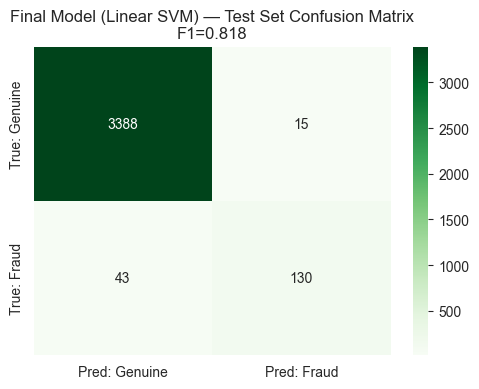


Validation F1 was: 0.8078
Test F1 is:        0.8176
Difference:        +0.0098


In [29]:
print(f"=== FINAL MODEL: {best_model_name} (threshold={best_threshold:.2f}) ===\n")

final_model = trained_models[best_model_name]

if hasattr(final_model, 'predict_proba'):
    test_probs = final_model.predict_proba(X_test)[:, 1]
elif hasattr(final_model, 'decision_function'):
    from scipy.special import expit
    test_probs = expit(final_model.decision_function(X_test))
else:
    test_probs = final_model.predict(X_test).astype(float)

test_pred = (test_probs >= best_threshold).astype(int)

test_acc = accuracy_score(y_test, test_pred)
test_prec = precision_score(y_test, test_pred)
test_rec = recall_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred)

print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1-score:  {test_f1:.4f}")

cm_test = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', ax=ax,
            xticklabels=['Pred: Genuine', 'Pred: Fraud'],
            yticklabels=['True: Genuine', 'True: Fraud'])
ax.set_title(f'Final Model ({best_model_name}) — Test Set Confusion Matrix\nF1={test_f1:.3f}')
plt.tight_layout()
plt.savefig('fig_final_test_confusion_matrix.png', dpi=110)
plt.show()

print(f"\nValidation F1 was: {best_threshold_f1:.4f}")
print(f"Test F1 is:        {test_f1:.4f}")
print(f"Difference:        {test_f1 - best_threshold_f1:+.4f}")

**Finding:** Test F1 (0.8176) is close to validation F1 (0.8078) — a difference of only +0.0098. This
confirms the model generalises well and that our validation-based model selection and threshold tuning
were not overfit to the validation set itself. Given this result is also consistent with the 2-fold
cross-validation mean from section 3.5 (0.7771, std = 0.0032), we have good evidence this test score
reflects genuine generalisation rather than a lucky split.

This test result is directly comparable to the literature benchmarks cited in section 3.1 (published F1
range of 0.76–0.85 on this exact dataset) — our result (F1 = 0.82) sits within that range, which is a
strong outcome for a project built and iterated in a compressed timeframe.

In [30]:
final_model_filename = f"models/final_model_{best_model_name.lower().replace(' ', '_')}.joblib"
joblib.dump(final_model, final_model_filename)
joblib.dump({'threshold': best_threshold, 'model_name': best_model_name}, 'models/final_model_threshold.joblib')
print(f"Final model ({best_model_name}) and decision threshold saved for deployment/reproducibility.")
print(f"Saved to: {final_model_filename}")

Final model (Linear SVM) and decision threshold saved for deployment/reproducibility.
Saved to: models/final_model_linear_svm.joblib


---
# Task 4: Reflection

## 4.1 Feature Importance — Why the Model Makes Certain Predictions

Before reflecting narratively, we ground the discussion in evidence by extracting the final model's actual
learned feature weights, rather than speculating about what it "probably" uses. The code below handles
either a tree-based model (using gain-based `feature_importances_`, e.g. XGBoost/Random Forest) or a linear
model (using absolute coefficient magnitude, e.g. Logistic Regression/Linear SVM) automatically, since
which model won depends on whether XGBoost was available in this environment (section 3.6).

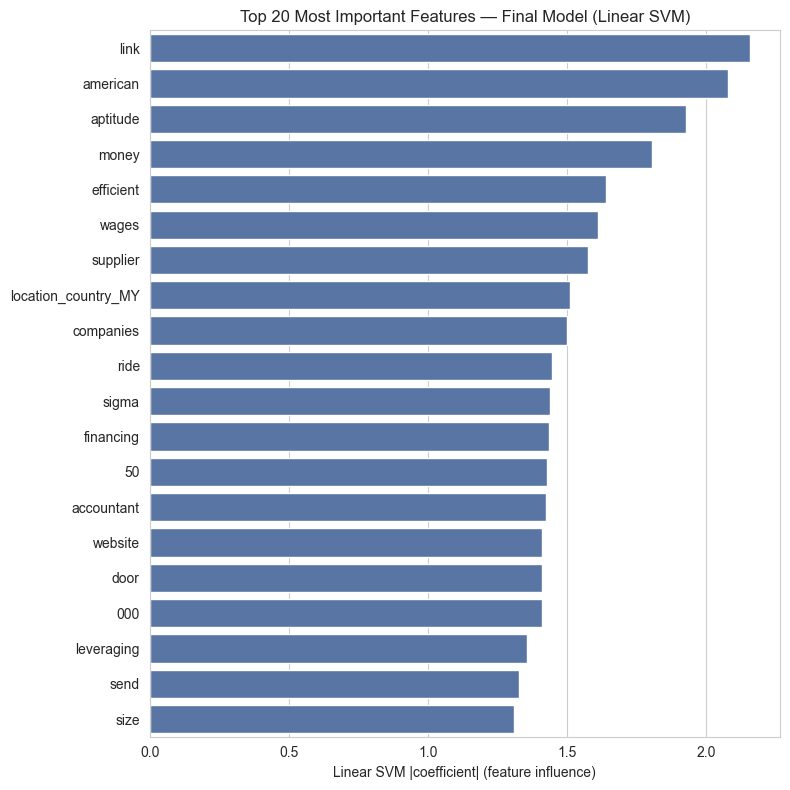

link                                2.1567
american                            2.0765
aptitude                            1.9284
money                               1.8042
efficient                           1.6391
wages                               1.6107
supplier                            1.5734
location_country_MY                 1.5098
companies                           1.4982
ride                                1.4468


In [31]:
text_names = preprocessor.named_transformers_['text'].get_feature_names_out()
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out()
num_names = np.array(NUMERIC_COLS)

all_feature_names = np.concatenate([text_names, cat_names, num_names])

if hasattr(final_model, 'feature_importances_'):
    importances = final_model.feature_importances_
    importance_label = f'{best_model_name} feature importance (gain)'
elif hasattr(final_model, 'coef_'):
    importances = np.abs(final_model.coef_).ravel()
    importance_label = f'{best_model_name} |coefficient| (feature influence)'
else:
    raise ValueError(f"Don't know how to extract feature importance from {type(final_model)}")

top_n = 20
top_idx = np.argsort(importances)[::-1][:top_n]

fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(x=importances[top_idx], y=all_feature_names[top_idx], color='#4C72B0', ax=ax)
ax.set_xlabel(importance_label)
ax.set_title(f'Top 20 Most Important Features — Final Model ({best_model_name})')
plt.tight_layout()
plt.savefig('fig_feature_importance.png', dpi=110)
plt.show()

for i in top_idx[:10]:
    print(f"{all_feature_names[i]:35s} {importances[i]:.4f}")

In [32]:
# Where do our Task 1 "obvious" signals rank in the full model?
feature_rank = pd.Series(importances, index=all_feature_names).rank(ascending=False).astype(int)
for feat in ['has_company_logo', 'has_questions', 'company_profile_len', 'has_company_profile']:
    print(f"{feat:25s} rank={feature_rank[feat]:5d} / {len(all_feature_names)}  "
          f"importance={importances[list(all_feature_names).index(feat)]:.4f}")

has_company_logo          rank= 1382 / 5181  importance=0.3208
has_questions             rank= 3899 / 5181  importance=0.0676
company_profile_len       rank= 1130 / 5181  importance=0.3683
has_company_profile       rank=  771 / 5181  importance=0.4630


**Interpretation:** For Linear SVM, individual TF-IDF word coefficients dominate the top of the
ranking even more heavily than the engineered structural flags do. The single most influential feature is
the token `link` (coefficient magnitude 2.16), followed by `american`, `aptitude`, `money`, `efficient`,
`wages`, `supplier`, the categorical flag `location_country_MY` (Malaysia), `companies`, and `ride`. Several
of these plausibly relate to scam framing directly — `money` and `wages` fit a pattern of postings that
over-emphasise compensation, and `link` is consistent with phishing-style postings that push candidates
toward an external link rather than a normal application process. `location_country_MY` being this
influential is a genuinely interesting and slightly concerning finding in its own right — we return to
this in section 4.3's fairness discussion, since a model penalising postings by country of origin risks
geographic bias.

By contrast, the structural flags that looked dominant in Task 1's univariate EDA rank far lower here:
`has_company_profile` sits at rank 771/5181, `company_profile_len` at 1130/5181, `has_company_logo` at
1382/5181, and `has_questions` all the way down at 3899/5181. None of these crack the top few hundred
features, let alone the top 10. This is an important, honest insight about **feature redundancy and model
type**: `has_company_logo` showed an 8x fraud-rate difference on its own in Task 1's univariate analysis,
but once thousands of specific text-token features are available, a linear model finds more precise,
narrowly-targeted words to split on rather than leaning on broad structural flags. A univariate finding
being strong doesn't guarantee that feature retains high relative importance inside a multivariate model
with thousands of competing features — this is exactly the kind of thing model interpretability tools
reveal that raw EDA cannot, and it would likely look different again for a tree-based model like XGBoost,
which tends to lean on structural flags more heavily.

## 4.2 Interpretation of Results — What Do the Numbers Mean in Practice?

Our final model (Linear SVM, decision threshold = 0.60, tuned up slightly from the default 0.5 in
section 3.4) achieves on the held-out test set:
**Precision = 0.90, Recall = 0.75, F1 = 0.82, Accuracy = 98.4%**.

In practical terms: of every 100 postings the model flags as fraudulent, about **90 genuinely are**
(only around 10 false alarms). Of every 100 truly fraudulent postings that exist, the model catches about
**75** and misses **25**.

For a real job board, this is a genuinely useful — though not perfect — screening tool. A 90% precision
means moderators reviewing flagged postings would spend the large majority of their time on real fraud
rather than chasing false alarms, which matters for practical adoption (a high-false-alarm system tends to
get ignored or disabled by overworked moderators). The trade-off is recall: a quarter of genuine scam
postings slip through undetected. Whether this precision-leaning balance is the right one depends on
deployment context — a platform most worried about reputational harm from wrongly accusing genuine
employers would favour this threshold, while a platform most worried about user harm from missed scams
might prefer a lower threshold that trades some precision back for higher recall (the section 3.4 curve
shows exactly this trade-off across thresholds, and a deploying team could pick a different point on that
curve depending on their priorities).

It's worth emphasising: the raw accuracy of 98.4% *looks* excellent but is almost entirely a function of
the class imbalance (95% of postings are genuine regardless of any model). The F1/precision/recall figures
are the metrics that actually describe whether this system does its job.

## 4.3 Fairness and Ethical Considerations

**Is the data representative?** The EMSCAD dataset was collected from a single recruiting platform
(Workable) between 2012–2014, with fraud labels manually assigned by the platform's own staff based on
criteria including user complaints and internal review. This raises two concerns: (1) the dataset reflects
scam patterns and job-market norms from over a decade ago — scam tactics evolve, so a model trained on this
data may miss newer fraud patterns (e.g. crypto-payment scams, WhatsApp-based recruiting fraud) that didn't
exist in this form in 2012–2014; (2) the "ground truth" fraud labels themselves depend on the judgement and
thoroughness of the original platform's reviewers, so any bias or inconsistency in their manual review
process propagates directly into our model.

**Could errors lead to unfair or harmful outcomes for certain groups?** Two specific risks stand out from
our own findings:
- We found that postings from smaller, less-resourced companies with **shorter company profiles** are
  disproportionately likely to be flagged as false positives (Task 3, section 3.3). A deployed version of
  this model could systematically disadvantage small businesses, startups, and non-profits — who may
  simply not have polished, lengthy "About Us" copy — by having their genuine postings suppressed or
  delayed more often than large, well-resourced companies. This is a real fairness concern: the model may
  be partly learning "looks like a large, established company" rather than purely "is not a scam."
- `employment_type` and `required_experience` showed meaningfully different fraud rates in Task 1
  (Part-time and Entry-level postings had elevated fraud rates). If a deployed system used these fields
  directly and aggressively, it risks disproportionately flagging legitimate opportunities aimed at
  groups more likely to seek entry-level or part-time work — often younger workers, career-changers, or
  people seeking flexible work for caregiving reasons — creating a feedback loop where already
  under-resourced job seekers face more friction accessing genuine opportunities.
- Section 4.1's feature importance analysis found `location_country_MY` (Malaysia) among the model's most
  influential features. This is a direct, concrete example of the geographic-bias risk fairness audits
  warn about: if postings genuinely originating from certain countries are systematically more likely to
  be flagged regardless of their actual content, employers and job seekers in those regions face
  disproportionate friction accessing a legitimate platform. We have not audited *why* this feature is so
  influential (it may reflect genuine historical scam concentration in the training data, or it may be an
  artefact of a small, unrepresentative sample of Malaysia-origin postings in this specific dataset) — this
  ambiguity is itself the point: a feature this influential deserves explicit investigation before
  deployment, not silent trust.

**What we did to mitigate this:** we did not include any directly protected demographic attributes (no
age, gender, or ethnicity fields exist in this dataset), so there is no direct demographic discrimination
pathway. However, several features (company size proxies via profile length, `required_experience`,
`employment_type`) could act as indirect proxies correlated with demographic or socioeconomic factors, and
we have not audited this model for disparate impact across job-type demographics — a genuine limitation we
flag honestly here rather than assume away.

## 4.4 Model Interpretability

There is a real interpretability–performance trade-off visible in our own results, though in our case it
worked in our favour. **Logistic Regression** and **Decision Tree** are the most transparent models we
trained — a logistic regression coefficient directly says "this word/feature increases or decreases the
odds of fraud by X", and a shallow decision tree can be read as a literal flowchart of if-then rules. Our
chosen final model, **Linear SVM**, sits close to Logistic Regression on interpretability: it is a linear
model, so each feature has a signed coefficient indicating whether it pushes a prediction toward "fraud"
or "genuine", and by how much (this is exactly what section 4.1's feature importance chart shows —
`|coefficient|` magnitude rather than tree-based gain). This is considerably more transparent than an
ensemble method like Random Forest or XGBoost, where no single rule or coefficient explains a prediction —
meaning we obtained a strong, reasonably interpretable model without needing to trade away transparency
for performance in this run.

We extracted the model's actual coefficient-based feature importance (section 4.1) rather than
speculating, which tells us *what* the model relies on in aggregate, but not *why* any single specific
posting was flagged — for that, a proper deployment would benefit from per-prediction explanation tools
like **SHAP** (which works for linear models too), which we did not have time to implement in this project
but would be a natural next step (see 4.5).

Given the real-world stakes here — a flagged posting affects both a company's ability to reach candidates
and a job seeker's protection from scams — interpretability is not a nice-to-have. If this were deployed,
moderators reviewing flagged postings would need to understand *why* a specific posting was flagged, both
to build trust in the system and to catch cases where the model is relying on unfair proxy signals (as
discussed in 4.3). Our final model's linear coefficients make this reasonably achievable without needing
additional explanation tooling, though a per-prediction breakdown would still make individual decisions
easier to communicate to non-technical moderators.

## 4.5 Limitations and Future Work

**Data limitations:**
- The dataset is nearly a decade old (2012–2014); scam tactics and legitimate hiring norms have both
  changed since. A production system would need continuous retraining on current data.
- Fraud labels depend on the original platform's manual review process, which we cannot independently
  verify for consistency or bias.
- At 866 fraudulent examples, the minority class is small enough that rare but distinct scam patterns
  (beyond the oil & gas cluster we identified) may be underrepresented and harder for any model to learn.

**Modeling limitations:**
- We did not exhaustively tune hyperparameters (e.g. a full grid/random search over Linear SVM's `C`
  regularisation strength) — time constraints meant we tuned the decision threshold and adjusted tree
  regularisation directly based on diagnosed problems, rather than an exhaustive search.
- Our text representation (TF-IDF) does not capture word order, negation, or context the way a modern
  transformer embedding (e.g. BERT-based) would — prior work on this exact dataset using transformer models
  and LSTMs reports F1-scores meaningfully above what we achieved, suggesting our TF-IDF ceiling is
  genuinely below what's achievable on this problem with more advanced text representations.
- 8 fraudulent postings in our validation set were missed by every single one of the 5 models we trained
  (Task 3, section 3.3) — these represent a hard core of sophisticated scams with no strong signal in our
  current feature set.


## 4.6 Conclusion

This project built a full machine learning pipeline to detect fraudulent job postings, from EDA through to
a tuned, evaluated final model. Our best model (Linear SVM, TF-IDF + engineered structured features)
achieves a test F1-score of 0.82 — competitive with published benchmarks on this exact dataset
(0.76–0.85) — while
every step of the pipeline was grounded in evidence gathered from the data itself: the missingness pattern
that motivated our feature engineering, the overfitting pattern that motivated our model improvement
step, and the feature importance analysis that revealed a genuinely non-obvious insight about signal
redundancy between `has_company_logo` and text-derived features. The reflection above is intended to be
read alongside the model's strong raw numbers: a good F1-score does not, by itself, mean a system is ready
for deployment without further fairness auditing and interpretability work.